In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import utils
import seaborn as sns
from pathlib import Path

path_figs = "./Figs/"
Path(path_figs).mkdir(parents=True, exist_ok=True)

index_finger = utils.index_finger
conditions = utils.conditions
force_error_col = f'forceError{index_finger}'

epoch_order = ['washout', 'adaptation', 'test']
epoch_labels = {'washout': 'Washout', 'adaptation': 'Training', 'test': 'Test'}

# Fill in after collection, or leave None to keep every subject in subjs.csv
sub_nums = None

# sub_nums = [4]

utils.set_figure_style("1col")
sns.color_palette('colorblind')


[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [43]:
# reload utils
import importlib
importlib.reload(utils)


<module 'utils' from '/Users/amin/projects/LearningDynamics/ChordAdaptationDynamics/SingleFingerGainGeneralizationV2/utils.py'>

Load trial-level data from `DatPreProcessing.ipynb`.

Motor-space force error = `endForce/gain − targetForce/gain`
(`.dat` `endForce` is the gain-scaled visual cursor; `targetForce` is the visual target).

Plots are split by `adaptation_condition` (the target trained in that cycle).


In [44]:
subjs_path = utils.path_misc + 'subjs.csv'
if not Path(subjs_path).exists():
    raise FileNotFoundError(
        f"{subjs_path} not found. Run DatPreProcessing.ipynb after .dat files are copied in."
    )

subjs = pd.read_csv(subjs_path, sep='\t')

if sub_nums is not None:
    subjs = subjs[subjs['subNum'].isin(sub_nums)].reset_index(drop=True)

subjs_correct = utils.remove_error_trials(subjs).copy()
subjs_correct['epoch'] = pd.Categorical(
    subjs_correct['block_type'].map(epoch_labels),
    categories=[epoch_labels[e] for e in epoch_order],
    ordered=True,
)
subjs_correct['block_type'] = pd.Categorical(
    subjs_correct['block_type'], categories=epoch_order, ordered=True,
)
subjs_correct


,subNum,BN,TN,TotalTrialNum,trial_num_within_block,trial_num_within_condition,cycle,block_type,adaptation_condition,targetForce1,...,gain,forceGain,trialCorr,trialErrorType,num_targets,chord,condition,day,count,epoch
0,1,1,1,1,1,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Washout
1,1,1,2,2,2,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Washout
2,1,1,3,3,3,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
3,1,1,4,4,4,2,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
4,1,1,5,5,5,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-2.0,1,1,Washout
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2795,5,12,56,556,56,14,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Test
2796,5,12,57,557,57,14,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Test
2797,5,12,58,558,58,15,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Test
2798,5,12,59,559,59,15,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test


In [45]:
subjs_correct.columns

Index(['subNum', 'BN', 'TN', 'TotalTrialNum', 'trial_num_within_block',
       'trial_num_within_condition', 'cycle', 'block_type',
       'adaptation_condition', 'targetForce1', 'targetForce2', 'targetForce3',
       'targetForce4', 'targetForce5', 'endForce1', 'endForce2', 'endForce3',
       'endForce4', 'endForce5', 'producedForce1', 'producedForce2',
       'producedForce3', 'producedForce4', 'producedForce5', 'expectedForce1',
       'expectedForce2', 'expectedForce3', 'expectedForce4', 'expectedForce5',
       'forceError1', 'forceError2', 'forceError3', 'forceError4',
       'forceError5', 'isTargetVisible', 'gain', 'forceGain', 'trialCorr',
       'trialErrorType', 'num_targets', 'chord', 'condition', 'day', 'count',
       'epoch'],
      dtype='str')

### Error rates


In [46]:
subjs_err = (
    subjs.groupby(['subNum', 'block_type', 'trialCorr'])
    .size()
    .reset_index(name='num_trials')
    .sort_values(['subNum', 'block_type', 'trialCorr'])
)
subjs_err


,subNum,block_type,trialCorr,num_trials
0,1,adaptation,0,10
1,1,adaptation,1,150
2,1,test,0,16
3,1,test,1,224
4,1,washout,0,13
5,1,washout,1,147
6,2,adaptation,0,17
7,2,adaptation,1,143
8,2,test,0,21
9,2,test,1,219


## Index force error by adaptation condition

One figure per trained target (`adaptation_condition`). Panels: washout, training, test.
Lines are the trial target (`condition`); group mean ± SEM.


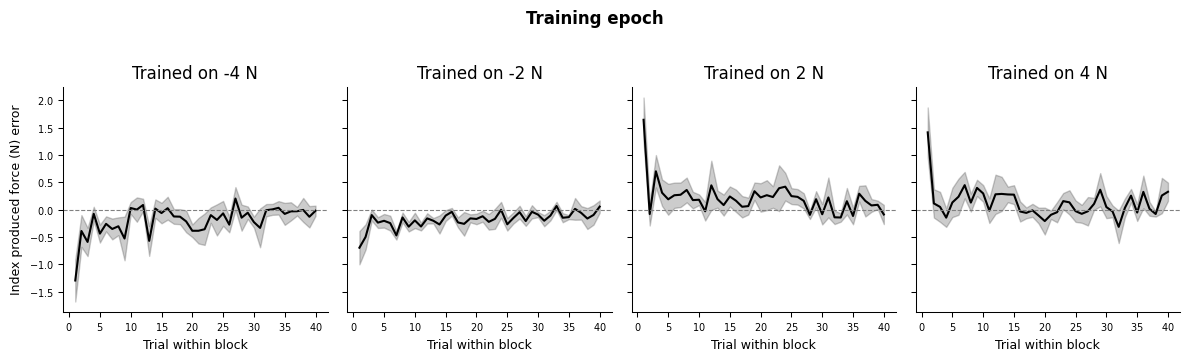

In [47]:
# Training (adaptation) only — one panel per trained target


fig, axs = plt.subplots(1, len(conditions), figsize=(12, 3.5), sharey=True)

for idx, adapt_cond in enumerate(conditions):
    cycle_data = subjs_correct[subjs_correct['adaptation_condition'] == adapt_cond]
    if cycle_data.empty:
        continue

    epoch_data = cycle_data[cycle_data['epoch'] == 'Training']
    ax = axs[idx]
    sns.lineplot(
        data=epoch_data,
        x='trial_num_within_block',
        y='forceError2',
        errorbar='se',
        ax=ax,
        color='black',
    )
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} N')
    ax.set_xlabel('Trial within block')
    ax.set_ylabel('Index produced force (N) error' if idx == 0 else '')


sns.despine()
fig.suptitle('Training epoch', y=1.02)
plt.tight_layout()
plt.savefig(path_figs + 'index_produced_force_training.pdf', bbox_inches='tight')
plt.show()


In [48]:
subjs_correct

,subNum,BN,TN,TotalTrialNum,trial_num_within_block,trial_num_within_condition,cycle,block_type,adaptation_condition,targetForce1,...,gain,forceGain,trialCorr,trialErrorType,num_targets,chord,condition,day,count,epoch
0,1,1,1,1,1,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Washout
1,1,1,2,2,2,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Washout
2,1,1,3,3,3,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
3,1,1,4,4,4,2,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
4,1,1,5,5,5,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-2.0,1,1,Washout
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2795,5,12,56,556,56,14,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Test
2796,5,12,57,557,57,14,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Test
2797,5,12,58,558,58,15,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Test
2798,5,12,59,559,59,15,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test


### Washout vs test: median produced force by target condition

X positions use the actual target force values (spacing −4→−2→2→4 is proportional).
Solid = washout, dashed = test.


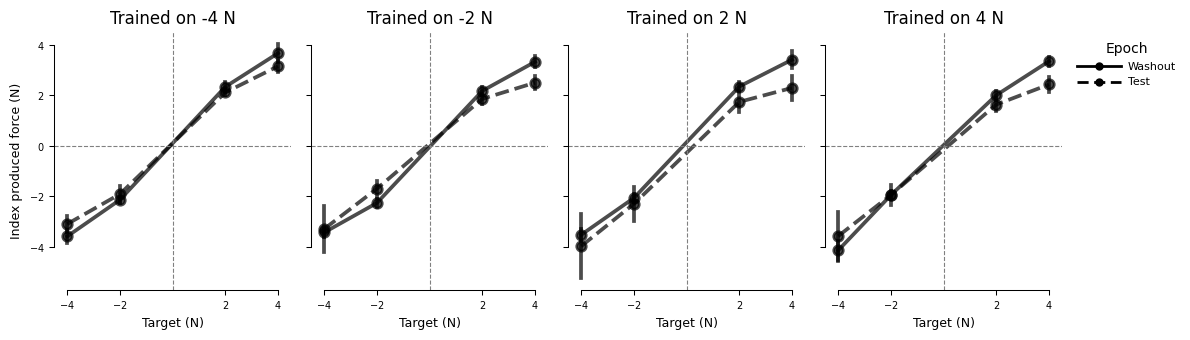

In [49]:
from matplotlib.lines import Line2D

epoch_line_style = {
    'washout': 'solid',
    'test': 'dashed',
}

fig, axs = plt.subplots(1, len(conditions), figsize=(12, 3.5), sharey=True)


for idx, adapt_cond in enumerate(conditions):
    cycle_data = subjs_correct[subjs_correct['adaptation_condition'] == adapt_cond]
    if cycle_data.empty:
        continue

    ax = axs[idx]
    for epoch, ls in epoch_line_style.items():
        epoch_data = cycle_data[cycle_data['block_type'] == epoch]
        if epoch_data.empty:
            continue
        grouped_data = (
            epoch_data.groupby(['subNum', 'condition'], as_index=False)['producedForce2']
            .median()
        )
        # native_scale keeps numeric spacing (-4,-2,2,4)
        sns.pointplot(
            data=grouped_data,
            x='condition',
            y='producedForce2',
            errorbar='se',
            native_scale=True,
            ax=ax,
            linestyles=ls,
            color='black',
            alpha=0.7,
        )

    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} N')
    ax.set_xlabel('Target (N)')
    ax.set_xticks(conditions)
    ax.set_xlim(min(conditions) - 0.5, max(conditions) + 0.5)
    if idx == 0:
        ax.set_ylabel('Index produced force (N)')
    else:
        ax.set_ylabel('')

legend_handles = [
    Line2D([0], [0], color='black', linestyle='-', linewidth=2, marker='o',
           markersize=5, label='Washout'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, marker='o',
           markersize=5, dashes=(4, 2), label='Test'),
]
leg = axs[-1].legend(
    handles=legend_handles,
    title='Epoch',
    loc='upper left',
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    handlelength=4,
    handletextpad=0.6,
)


sns.despine(trim=True)
plt.tight_layout()
plt.savefig(path_figs + 'produced_force_washout_vs_test.pdf', bbox_inches='tight')
plt.show()


### Mean index force error (± SEM) by epoch, split by adaptation condition


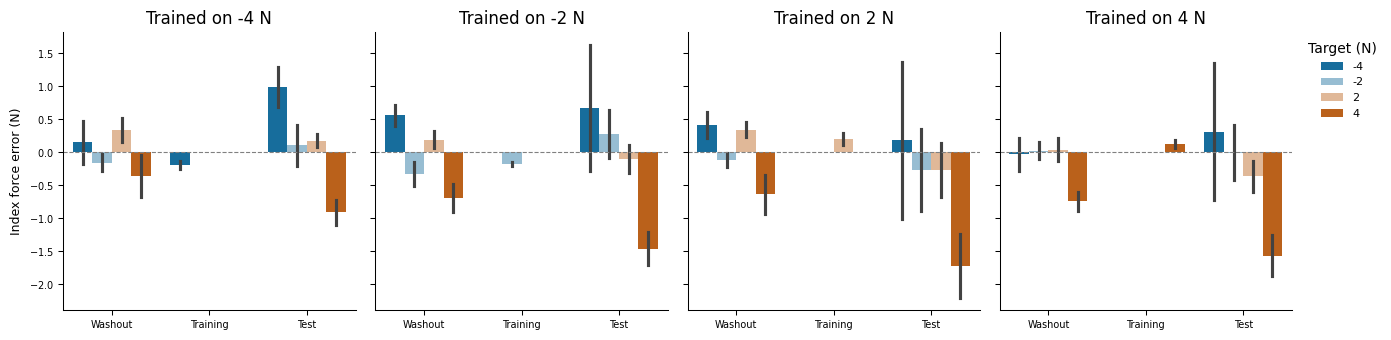

In [50]:
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]
# Larger |target| → higher opacity
condition_palette = {
    -4: with_opacity(cb[0], 1.0),
    -2: with_opacity(cb[0], 0.45),
     2: with_opacity(cb[3], 0.45),
     4: with_opacity(cb[3], 1.0),
}

subj_means = (
    subjs_correct.groupby(
        ['subNum', 'adaptation_condition', 'epoch', 'condition'],
        observed=True,
    )[force_error_col]
    .mean()
    .reset_index()
)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, adapt_cond in zip(axs, conditions):
    plot_data = subj_means[subj_means['adaptation_condition'] == adapt_cond]
    sns.barplot(
        data=plot_data,
        x='epoch',
        y=force_error_col,
        hue='condition',
        hue_order=conditions,
        palette=condition_palette,
        errorbar='se',
        ax=ax,
    )
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} N')
    ax.set_xlabel('')
    ax.set_ylabel('Index force error (N)' if ax is axs[0] else '')
    if ax is not axs[-1] and ax.legend_ is not None:
        ax.legend_.remove()
    elif ax.legend_ is not None:
        ax.legend(title='Target (N)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'index_force_error_mean_by_adapt.pdf', bbox_inches='tight')
plt.show()


### Aftereffect: test − washout

Within each `subNum`, `adaptation_condition`, and target `condition`, subtract the washout mean from the test mean (index produced force).


In [25]:
subjs['block_type'].value_counts()

block_type
test          1200
washout        800
adaptation     800
Name: count, dtype: int64

In [27]:
subjs_correct['epoch'].value_counts()

epoch
Test        1127
Washout      751
Training     743
Name: count, dtype: int64

In [58]:
epoch_means = (
    subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])]
    .groupby(
        ['subNum', 'adaptation_condition', 'condition', 'epoch'],
        observed=True,
    )['producedForce2']
    .mean()
    .unstack('epoch')
)

epoch_means['test_minus_washout'] = epoch_means['Test'] - epoch_means['Washout']
aftereffect = epoch_means.reset_index()
aftereffect.iloc[:20]


epoch,subNum,adaptation_condition,condition,Washout,Test,test_minus_washout
0,1,-4.0,-4.0,-4.635800,-3.356429,1.279371
1,1,-4.0,-2.0,-2.137300,-2.212867,-0.075567
2,1,-4.0,2.0,1.897600,2.343071,0.445471
3,1,-4.0,4.0,4.337500,3.688714,-0.648786
4,1,-2.0,-4.0,-3.151900,-2.278357,0.873543
5,1,-2.0,-2.0,-2.041000,-1.472867,0.568133
6,1,-2.0,2.0,1.941111,2.141500,0.200389
7,1,-2.0,4.0,3.892857,2.597733,-1.295124
8,1,2.0,-4.0,-3.084100,-4.669154,-1.585054
9,1,2.0,-2.0,-2.308714,-3.930500,-1.621786


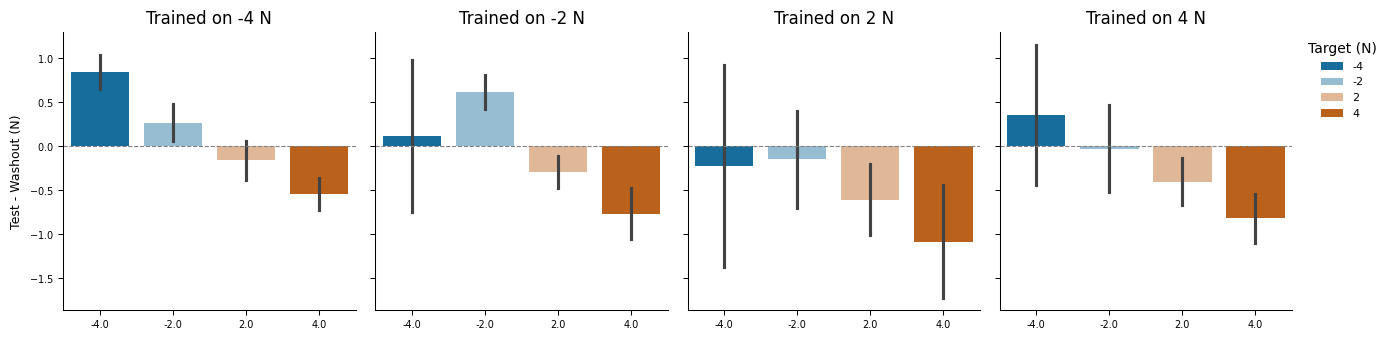

In [60]:
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]
# Larger |target| → higher opacity
condition_palette = {
    -4: with_opacity(cb[0], 1.0),
    -2: with_opacity(cb[0], 0.45),
     2: with_opacity(cb[3], 0.45),
     4: with_opacity(cb[3], 1.0),
}

fig, axs = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, adapt_cond in zip(axs, conditions):
    plot_data = aftereffect[aftereffect['adaptation_condition'] == adapt_cond]
    sns.barplot(
        data=plot_data,
        x='condition',
        y='test_minus_washout',
        hue='condition',
        hue_order=conditions,
        palette=condition_palette,
        errorbar='se',
        ax=ax,
    )
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} N')
    ax.set_xlabel('')
    ax.set_ylabel('Test - Washout (N)' if ax is axs[0] else '')
    if ax is not axs[-1] and ax.legend_ is not None:
        ax.legend_.remove()
    elif ax.legend_ is not None:
        ax.legend(title='Target (N)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
# plt.savefig(path_figs + 'index_force_error_mean_by_adapt.pdf', bbox_inches='tight')
plt.show()
